In [1]:
import  numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

In [2]:
df=pd.read_csv("C:/Users/alokk/Downloads/emojify_data.csv")
df.head()

,French macaroon is so tasty,4
0,work is horrible,3
1,I am upset,3
2,throw the ball,1
3,Good joke,2
4,what is your favorite baseball game,1


In [3]:
df.columns=["text","Level"]
df.head()

,text,Level
0,work is horrible,3
1,I am upset,3
2,throw the ball,1
3,Good joke,2
4,what is your favorite baseball game,1


In [4]:
df["Level"].value_counts()

Level
2    56
3    52
0    33
4    22
1    19
Name: count, dtype: int64

In [5]:
# df.isnull().sum()

<Axes: xlabel='Level', ylabel='count'>

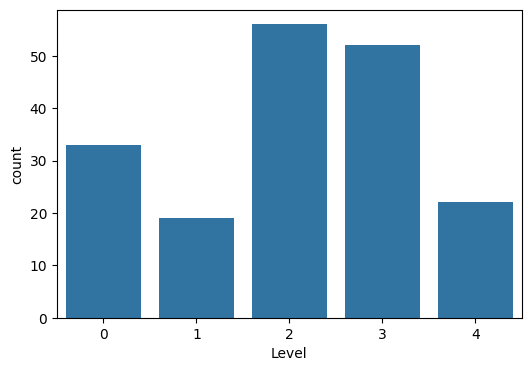

In [6]:
plt.figure(figsize=(6,4))
sns.countplot(x="Level",data=df)

In [7]:
emoji={ 0: "❤️",
    1: "⚾",
    2: "😄",
    3: "😞",
    4: "🍴"

}
df["emoji"]=df["Level"].map(emoji)
df.head()

,text,Level,emoji
0,work is horrible,3,😞
1,I am upset,3,😞
2,throw the ball,1,⚾
3,Good joke,2,😄
4,what is your favorite baseball game,1,⚾


In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer

t = TfidfVectorizer()

x = t.fit_transform(df["text"])

x.shape

(182, 307)

In [9]:
from sklearn.model_selection import train_test_split 
y=df["Level"]
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [10]:
from sklearn.linear_model import LogisticRegression
model=LogisticRegression()
model.fit(x_train,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [11]:
model.score(x_train,y_train)

0.896551724137931

In [12]:
text=" i am good "
pred=model.predict(t.transform([text]))
print("Label:", pred[0])

print("Emoji:", emoji[pred[0]])

Label: 2
Emoji: 😄


In [13]:
model.score(x_test,y_test)

0.4864864864864865

In [14]:
import pickle 
pickle.dump(model,open("emojin_model.pkl","wb"))
pickle.dump(t, open("tfidf.pkl", "wb"))
print("successfully")

successfully
